# CO1.4 Modeling - Part 4 (YOLO + DeepSORT)
* Shafer Arjun Tagorda

## Pre-Requisites/Preparations

In [1]:
%pip install "setuptools<82" deep-sort-realtime

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import itertools
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from ultralytics import YOLO
from deep_sort_realtime.deepsort_tracker import DeepSort

PROJECT_ROOT = Path("/home/arjun/lli-pedestrian")
SEQUENCE_DIR = PROJECT_ROOT / "data" / "mot" / "MOT17" / "train" / "MOT17-04-FRCNN"

OUTPUT_DIR = PROJECT_ROOT / "runs" / "deepsort_continuous"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

LLVIP_WEIGHTS = (
    PROJECT_ROOT / "runs" / "pedestrian_zerodce_yolo11n_notebook" / "weights" / "best.pt"
)
DETECTORS = {
    "YOLO11n (LLVIP-trained)": LLVIP_WEIGHTS,
    "YOLO11n (COCO-pretrained)": "yolo11n.pt",   
}
DETECTORS = {
    name: weights
    for name, weights in DETECTORS.items()
    if str(weights) == "yolo11n.pt" or Path(weights).exists()
}

DETECTION_CONF = 0.25
DETECTION_IOU = 0.70
DETECTION_IMGSZ = 1280      
DETECTION_DEVICE = 0 if torch.cuda.is_available() else "cpu"

DEFAULT_TRACKER_PARAMS = dict(
    max_age=30,
    n_init=3,
    nms_max_overlap=1.0,
    max_cosine_distance=0.2,
    max_iou_distance=0.7,
    nn_budget=100,
)
SWEEPS = {   
    "max_age": [5, 15, 30, 60],
    "n_init": [1, 3, 5],
    "max_cosine_distance": [0.1, 0.2, 0.4, 0.6],
    "max_iou_distance": [0.5, 0.7, 0.9],
}
RUN_FULL_GRID = False       
FRAME_STEPS = [1, 2, 3, 5, 10, 20]   

EVAL_IOU = 0.50
PEDESTRIAN_CLASS = 1
IGNORE_CLASSES = {2, 7, 8, 12}   
LLVIP_REFERENCE_PCT = 7.313      

RUN_DETECTION = True    
MAX_FRAMES = None       

SYSTEM_YOLO = "YOLOv11 only"
SYSTEM_DS = "YOLOv11 + DeepSORT"
SYSTEM_DS_COAST = "YOLOv11 + DeepSORT (incl. predicted)"
SYSTEM_ORDER = [SYSTEM_YOLO, SYSTEM_DS, SYSTEM_DS_COAST]
SYSTEM_COLORS = {SYSTEM_YOLO: "#1f77b4", SYSTEM_DS: "#2ca02c", SYSTEM_DS_COAST: "#ff7f0e"}
DETECTOR_COLORS = ["#1f77b4", "#d62728", "#9467bd", "#8c564b"]

print("Sequence:", SEQUENCE_DIR, "| exists:", SEQUENCE_DIR.exists())
print("Detectors:", list(DETECTORS))
print("Outputs:", OUTPUT_DIR)

Sequence: /home/arjun/lli-pedestrian/data/mot/MOT17/train/MOT17-04-FRCNN | exists: False
Detectors: ['YOLO11n (LLVIP-trained)', 'YOLO11n (COCO-pretrained)']
Outputs: /home/arjun/lli-pedestrian/runs/deepsort_continuous


## DeepSORT

In [ ]:
seqinfo = {}
ini_path = SEQUENCE_DIR / "seqinfo.ini"
if ini_path.exists():
    for line in ini_path.read_text().splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            seqinfo[key.strip()] = value.strip()

IMAGE_DIR = SEQUENCE_DIR / "img1"
image_paths = sorted(
    p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
if MAX_FRAMES:
    image_paths = image_paths[:MAX_FRAMES]
if not image_paths:
    raise FileNotFoundError(f"No frames found in {IMAGE_DIR}")

frames_df = pd.DataFrame(
    {
        "frame_index": np.arange(len(image_paths)),
        "frame_number": [int(p.stem) for p in image_paths],
        "image_name": [p.name for p in image_paths],
    }
)
frame_numbers = frames_df["frame_number"].tolist()
FRAME_RATE = float(seqinfo.get("frameRate", 30))

sample = cv2.imread(str(image_paths[0]))
IM_HEIGHT, IM_WIDTH = sample.shape[:2]

gt_all = pd.read_csv(
    SEQUENCE_DIR / "gt" / "gt.txt",
    header=None,
    names=["frame", "id", "x", "y", "w", "h", "conf", "cls", "vis"],
)
gt_all = gt_all[gt_all["frame"].isin(frame_numbers)].copy()
gt_all["x1"], gt_all["y1"] = gt_all["x"], gt_all["y"]
gt_all["x2"], gt_all["y2"] = gt_all["x"] + gt_all["w"], gt_all["y"] + gt_all["h"]

gt_eval_df = gt_all[(gt_all["cls"] == PEDESTRIAN_CLASS) & (gt_all["conf"] == 1)]
ignore_df = gt_all[gt_all["cls"].isin(IGNORE_CLASSES)]

print(f"Frames: {len(frames_df)} | frame rate: {FRAME_RATE:g} fps | size: {IM_WIDTH}x{IM_HEIGHT}")
print(f"Evaluated pedestrian boxes: {len(gt_eval_df)} | identities: {gt_eval_df['id'].nunique()}")
print(f"Ignore-region boxes: {len(ignore_df)}")

Frames: 1050 | frame rate: 30 fps | size: 1920x1080
Evaluated pedestrian boxes: 47557 | identities: 83
Ignore-region boxes: 4798


In [ ]:
EMPTY = (np.zeros(0, dtype=int), np.zeros((0, 4)))


def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def box_iou_matrix(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-9)


def to_frame_dict(df, id_col=None):
    out = {}
    if df is None or len(df) == 0:
        return out
    next_id = 0
    for frame, group in df.groupby("frame"):
        boxes = group[["x1", "y1", "x2", "y2"]].to_numpy(dtype=float)
        if id_col:
            ids = group[id_col].to_numpy()
        else:
            ids = np.arange(next_id, next_id + len(group))
            next_id += len(group)
        out[int(frame)] = (ids, boxes)
    return out


def drop_ignored_predictions(pred_boxes, gt_boxes, ignore_boxes, thr):
    keep = np.ones(len(pred_boxes), dtype=bool)
    if len(pred_boxes) == 0 or len(ignore_boxes) == 0:
        return keep
    matched = np.zeros(len(pred_boxes), dtype=bool)
    if len(gt_boxes):
        iou = box_iou_matrix(pred_boxes, gt_boxes)
        score = np.where(iou >= thr, iou, 0.0)
        rows, cols = linear_sum_assignment(-score)
        for r, c in zip(rows, cols):
            if score[r, c] > 0:
                matched[r] = True
    on_ignore = box_iou_matrix(pred_boxes, ignore_boxes).max(axis=1) >= thr
    return ~((~matched) & on_ignore)


def evaluate_sequence(frames, gt_dict, ignore_dict, pred_dict, thr=EVAL_IOU):
    tp = fp = fn = idsw = frag = 0
    iou_sum = 0.0
    num_gt = num_pred = 0
    prev_tracker = {}       
    prev_step = {}         
    gt_frames, tracked_frames = {}, {}
    ever_tracked, last_tracked = set(), {}
    id_overlap = {}
    pred_ids_seen = set()

    for f in frames:
        g_ids, g_boxes = gt_dict.get(f, EMPTY)
        p_ids, p_boxes = pred_dict.get(f, EMPTY)
        _, i_boxes = ignore_dict.get(f, EMPTY)

        keep = drop_ignored_predictions(p_boxes, g_boxes, i_boxes, thr)
        p_ids, p_boxes = p_ids[keep], p_boxes[keep]
        num_gt += len(g_ids)
        num_pred += len(p_ids)
        pred_ids_seen.update(p_ids.tolist())
        for gid in g_ids:
            gt_frames[gid] = gt_frames.get(gid, 0) + 1

        matches = []
        sim = np.zeros((len(g_ids), len(p_ids)))
        if len(g_ids) and len(p_ids):
            sim = box_iou_matrix(g_boxes, p_boxes)
            for a, b in zip(*np.nonzero(sim >= thr)):
                key = (g_ids[a], p_ids[b])
                id_overlap[key] = id_overlap.get(key, 0) + 1

            bonus = np.zeros_like(sim)
            for a, gid in enumerate(g_ids):
                previous = prev_step.get(gid)
                if previous is not None:
                    bonus[a] = (p_ids == previous)
            score = 1000.0 * bonus + sim
            score[sim < thr - 1e-9] = 0.0
            rows, cols = linear_sum_assignment(-score)
            matches = [(a, b) for a, b in zip(rows, cols) if score[a, b] > 1e-9]

        tp += len(matches)
        fn += len(g_ids) - len(matches)
        fp += len(p_ids) - len(matches)
        matched_now = {}
        for a, b in matches:
            gid, pid = g_ids[a], p_ids[b]
            iou_sum += sim[a, b]
            if gid in prev_tracker and prev_tracker[gid] != pid:
                idsw += 1
            prev_tracker[gid] = pid
            matched_now[gid] = pid

        for gid in g_ids:
            tracked = gid in matched_now
            if tracked:
                tracked_frames[gid] = tracked_frames.get(gid, 0) + 1
                if last_tracked.get(gid) is False and gid in ever_tracked:
                    frag += 1
                ever_tracked.add(gid)
            last_tracked[gid] = tracked
            prev_step[gid] = matched_now.get(gid)

    idtp = 0
    if id_overlap:
        g_index = {gid: i for i, gid in enumerate(sorted({k[0] for k in id_overlap}))}
        p_index = {pid: i for i, pid in enumerate(sorted({k[1] for k in id_overlap}))}
        overlap = np.zeros((len(g_index), len(p_index)))
        for (gid, pid), count in id_overlap.items():
            overlap[g_index[gid], p_index[pid]] = count
        rows, cols = linear_sum_assignment(-overlap)
        idtp = int(overlap[rows, cols].sum())
    idfn, idfp = num_gt - idtp, num_pred - idtp

    ratios = np.array([tracked_frames.get(gid, 0) / n for gid, n in gt_frames.items()])
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    return {
        "GT boxes": num_gt,
        "Boxes produced": num_pred,
        "TP": tp, "FP": fp, "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": 2 * precision * recall / (precision + recall) if (precision + recall) else float("nan"),
        "MODA": 1 - (fn + fp) / num_gt if num_gt else float("nan"),
        "MOTA": 1 - (fn + fp + idsw) / num_gt if num_gt else float("nan"),
        "MOTP (mean IoU)": iou_sum / tp if tp else float("nan"),
        "IDF1": 2 * idtp / (2 * idtp + idfp + idfn) if (2 * idtp + idfp + idfn) else float("nan"),
        "IDP": idtp / (idtp + idfp) if (idtp + idfp) else float("nan"),
        "IDR": idtp / (idtp + idfn) if (idtp + idfn) else float("nan"),
        "ID switches": idsw,
        "Fragmentations": frag,
        "Mostly tracked": int((ratios > 0.8).sum()),
        "Partially tracked": int(((ratios >= 0.2) & (ratios <= 0.8)).sum()),
        "Mostly lost": int((ratios < 0.2).sum()),
        "GT identities": len(gt_frames),
        "Predicted identities": len(pred_ids_seen),
    }


gt_dict = to_frame_dict(gt_eval_df, id_col="id")
ignore_dict = to_frame_dict(ignore_df, id_col="id")


def best_iou_to_previous_frame(boxes_by_frame, frames):
    values = []
    for previous, current in zip(frames[:-1], frames[1:]):
        current_boxes = boxes_by_frame.get(current, EMPTY)[1]
        previous_boxes = boxes_by_frame.get(previous, EMPTY)[1]
        if len(current_boxes) == 0:
            continue
        if len(previous_boxes) == 0:
            values.extend([0.0] * len(current_boxes))
        else:
            values.extend(box_iou_matrix(current_boxes, previous_boxes).max(axis=1))
    return np.array(values)

,Median best IoU with previous frame,Boxes with IoU >= 0.3 (%)
Footage,,
MOT17-04-FRCNN,0.985,99.922
LLVIP test frames (earlier run),0.000,7.313


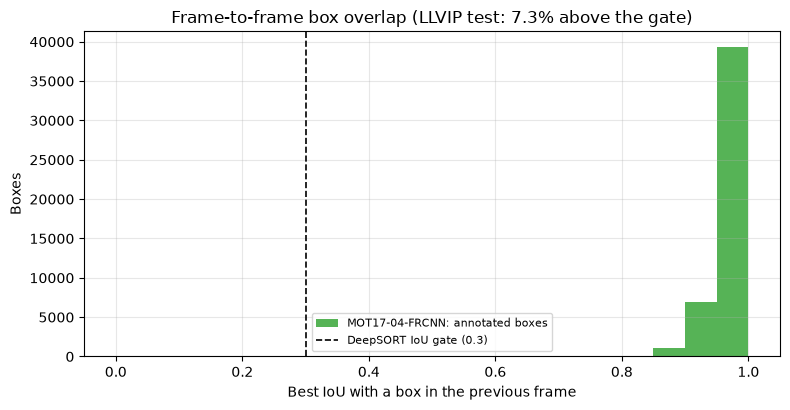

In [ ]:
continuity_values = best_iou_to_previous_frame(gt_dict, frame_numbers)
continuity_pct = float((continuity_values >= 0.3).mean() * 100)

display(
    pd.DataFrame(
        {
            "Footage": [SEQUENCE_DIR.name, "LLVIP test frames (earlier run)"],
            "Median best IoU with previous frame": [float(np.median(continuity_values)), 0.0],
            "Boxes with IoU >= 0.3 (%)": [continuity_pct, LLVIP_REFERENCE_PCT],
        }
    ).set_index("Footage").round(3)
)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(continuity_values, bins=np.linspace(0, 1, 21), color="#2ca02c", alpha=0.8,
        label=f"{SEQUENCE_DIR.name}: annotated boxes")
ax.axvline(0.3, color="black", linestyle="--", linewidth=1.2, label="DeepSORT IoU gate (0.3)")
ax.set_xlabel("Best IoU with a box in the previous frame")
ax.set_ylabel("Boxes")
ax.set_title(f"Frame-to-frame box overlap (LLVIP test: {LLVIP_REFERENCE_PCT:.1f}% above the gate)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "01_continuity")
plt.show()

In [ ]:
# Run each detector once over the sequence and cache detections plus appearance embeddings.

def slugify(name):
    return "".join(ch.lower() if ch.isalnum() else "_" for ch in name).strip("_")


embedder_holder = {}


def get_embedder():
    if "tracker" not in embedder_holder:
        embedder_holder["tracker"] = DeepSort(
            max_age=1, embedder="mobilenet", half=torch.cuda.is_available()
        )
    return embedder_holder["tracker"]


def run_detector(name, weights):
    slug = slugify(name)
    det_csv = OUTPUT_DIR / f"detections_{slug}.csv"
    emb_npy = OUTPUT_DIR / f"embeddings_{slug}.npy"
    time_csv = OUTPUT_DIR / f"timing_{slug}.csv"

    if not RUN_DETECTION and det_csv.exists() and emb_npy.exists() and time_csv.exists():
        return pd.read_csv(det_csv), np.load(emb_npy), pd.read_csv(time_csv)

    model = YOLO(str(weights))
    embedder = get_embedder()
    rows, embedding_chunks, timing = [], [], []

    for row in tqdm(frames_df.itertuples(index=False), total=len(frames_df), desc=name):
        frame = cv2.imread(str(IMAGE_DIR / row.image_name))

        start = time.perf_counter()
        result = model.predict(
            frame, conf=DETECTION_CONF, iou=DETECTION_IOU, imgsz=DETECTION_IMGSZ,
            classes=[0], device=DETECTION_DEVICE, verbose=False,
        )[0]
        boxes = result.boxes.xyxy.detach().cpu().numpy()
        confidences = result.boxes.conf.detach().cpu().numpy()
        detect_ms = (time.perf_counter() - start) * 1000.0

        raw = []
        for box, confidence in zip(boxes, confidences):
            x1, y1, x2, y2 = (float(v) for v in box)
            if x2 <= x1 or y2 <= y1:
                continue
            rows.append({"frame": row.frame_number, "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                         "conf": float(confidence)})
            raw.append(([x1, y1, x2 - x1, y2 - y1], float(confidence), "person"))

        start = time.perf_counter()
        if raw:
            embedding_chunks.append(np.asarray(embedder.generate_embeds(frame, raw)))
        embed_ms = (time.perf_counter() - start) * 1000.0
        timing.append({"frame": row.frame_number, "detector_ms": detect_ms, "embedding_ms": embed_ms})

    det_df = pd.DataFrame(rows, columns=["frame", "x1", "y1", "x2", "y2", "conf"])
    embeddings = (
        np.concatenate(embedding_chunks) if embedding_chunks else np.zeros((0, 1))
    )
    if len(embeddings) != len(det_df):
        raise RuntimeError(
            f"Got {len(embeddings)} embeddings for {len(det_df)} detections; "
            "check the installed deep-sort-realtime version."
        )

    timing_df = pd.DataFrame(timing)
    det_df.to_csv(det_csv, index=False)
    np.save(emb_npy, embeddings)
    timing_df.to_csv(time_csv, index=False)
    return det_df, embeddings, timing_df


detector_outputs = {}
for detector_name, detector_weights in DETECTORS.items():
    det_df, embeddings, timing_df = run_detector(detector_name, detector_weights)
    detector_outputs[detector_name] = {"det": det_df, "emb": embeddings, "timing": timing_df}
    print(f"{detector_name}: {len(det_df)} detections over {len(frames_df)} frames "
          f"({len(det_df) / len(frames_df):.1f} per frame)")

/home/arjun/lli-pedestrian/env/lib/python3.14/site-packages/deep_sort_realtime/embedder/embedder_pytorch.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


YOLO11n (LLVIP-trained):   0%|          | 0/1050 [00:00<?, ?it/s]

YOLO11n (LLVIP-trained): 37553 detections over 1050 frames (35.8 per frame)


YOLO11n (COCO-pretrained):   0%|          | 0/1050 [00:00<?, ?it/s]

YOLO11n (COCO-pretrained): 35979 detections over 1050 frames (34.3 per frame)


In [ ]:
def run_deepsort(det_df, embeddings, frames, params):
    tracker = DeepSort(embedder=None, **params)
    rows_by_frame = det_df.groupby("frame").indices
    box_values = det_df[["x1", "y1", "x2", "y2", "conf"]].to_numpy(dtype=float)

    records, update_times = [], []
    for f in frames:
        index = rows_by_frame.get(f, np.array([], dtype=int))
        raw = [
            ([b[0], b[1], b[2] - b[0], b[3] - b[1]], b[4], "person")
            for b in box_values[index]
        ]
        embeds = [embeddings[i] for i in index]

        start = time.perf_counter()
        tracks = tracker.update_tracks(raw, embeds=embeds)
        update_times.append((time.perf_counter() - start) * 1000.0)

        for track in tracks:
            if not track.is_confirmed():
                continue
            left, top, right, bottom = track.to_ltrb()
            left, right = (float(np.clip(v, 0, IM_WIDTH - 1)) for v in (left, right))
            top, bottom = (float(np.clip(v, 0, IM_HEIGHT - 1)) for v in (top, bottom))
            if right <= left or bottom <= top:
                continue
            records.append(
                {
                    "frame": f, "track_id": int(track.track_id),
                    "x1": left, "y1": top, "x2": right, "y2": bottom,
                    "time_since_update": int(track.time_since_update),
                    "updated": track.time_since_update == 0,
                }
            )

    columns = ["frame", "track_id", "x1", "y1", "x2", "y2", "time_since_update", "updated"]
    return pd.DataFrame(records, columns=columns), float(np.mean(update_times))


def evaluate_systems(det_df, tracks_df, frames):
    results = {}
    results[SYSTEM_YOLO] = evaluate_sequence(frames, gt_dict, ignore_dict, to_frame_dict(det_df))
    for key in ("MOTA", "IDF1", "IDP", "IDR", "ID switches", "Fragmentations",
                "Mostly tracked", "Partially tracked", "Mostly lost", "Predicted identities"):
        results[SYSTEM_YOLO][key] = float("nan")   
    updated = tracks_df[tracks_df["updated"]]
    results[SYSTEM_DS] = evaluate_sequence(frames, gt_dict, ignore_dict, to_frame_dict(updated, "track_id"))
    results[SYSTEM_DS_COAST] = evaluate_sequence(frames, gt_dict, ignore_dict, to_frame_dict(tracks_df, "track_id"))
    return results

## Evaluation

Boxes produced  \
Detector                  System                                                 
YOLO11n (LLVIP-trained)   YOLOv11 only                                   37206   
                          YOLOv11 + DeepSORT                             36347   
                          YOLOv11 + DeepSORT (incl. predicted)           46611   
YOLO11n (COCO-pretrained) YOLOv11 only                                   34964   
                          YOLOv11 + DeepSORT                             34030   
                          YOLOv11 + DeepSORT (incl. predicted)           43312   

                                                                   TP     FP  \
Detector                  System                                               
YOLO11n (LLVIP-trained)   YOLOv11 only                          29474   7732   
                          YOLOv11 + DeepSORT                    28978   7369   
                          YOLOv11 + DeepSORT (incl. predicted)  31689  14922   
YOLO11n (COCO-pretrained) YOLOv11 only                          29007   5957   
                          YOLOv11 + DeepSORT                    28505   5525   
                          YOLOv11 + DeepSORT (incl. predicted)  31092  12220   

                                                                   FN  \
Detector                  System                                        
YOLO11n (LLVIP-trained)   YOLOv11 only                          18083   
                          YOLOv11 + DeepSORT                    18579   
                          YOLOv11 + DeepSORT (incl. predicted)  15868   
YOLO11n (COCO-pretrained) YOLOv11 only                          18550   
                          YOLOv11 + DeepSORT                    19052   
                          YOLOv11 + DeepSORT (incl. predicted)  16465   

                                                                Precision  \
Detector                  System                                            
YOLO11n (LLVIP-trained)   YOLOv11 only                              0.792   
                          YOLOv11 + DeepSORT                        0.797   
                          YOLOv11 + DeepSORT (incl. predicted)      0.680   
YOLO11n (COCO-pretrained) YOLOv11 only                              0.830   
                          YOLOv11 + DeepSORT                        0.838   
                          YOLOv11 + DeepSORT (incl. predicted)      0.718   

                                                                Recall     F1  \
Detector                  System                                                
YOLO11n (LLVIP-trained)   YOLOv11 only                           0.620  0.695   
                          YOLOv11 + DeepSORT                     0.609  0.691   
                          YOLOv11 + DeepSORT (incl. predicted)   0.666  0.673   
YOLO11n (COCO-pretrained) YOLOv11 only                           0.610  0.703   
                          YOLOv11 + DeepSORT                     0.599  0.699   
                          YOLOv11 + DeepSORT (incl. predicted)   0.654  0.684   

                                                                 MODA   MOTA  \
Detector                  System                                               
YOLO11n (LLVIP-trained)   YOLOv11 only                          0.457    NaN   
                          YOLOv11 + DeepSORT                    0.454  0.450   
                          YOLOv11 + DeepSORT (incl. predicted)  0.353  0.349   
YOLO11n (COCO-pretrained) YOLOv11 only                          0.485    NaN   
                          YOLOv11 + DeepSORT                    0.483  0.479   
                          YOLOv11 + DeepSORT (incl. predicted)  0.397  0.393   

                                                                 IDF1  
Detector                  System                                       
YOLO11n (LLVIP-trained)   YOLOv11 only                            NaN  
                          YOLOv11 + DeepSORT              

ID switches  \
Detector                  System                                              
YOLO11n (LLVIP-trained)   YOLOv11 only                                  NaN   
                          YOLOv11 + DeepSORT                          221.0   
                          YOLOv11 + DeepSORT (incl. predicted)        191.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                  NaN   
                          YOLOv11 + DeepSORT                          218.0   
                          YOLOv11 + DeepSORT (incl. predicted)        172.0   

                                                                Fragmentations  \
Detector                  System                                                 
YOLO11n (LLVIP-trained)   YOLOv11 only                                     NaN   
                          YOLOv11 + DeepSORT                             615.0   
                          YOLOv11 + DeepSORT (incl. predicted)           304.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                     NaN   
                          YOLOv11 + DeepSORT                             676.0   
                          YOLOv11 + DeepSORT (incl. predicted)           261.0   

                                                                Mostly tracked  \
Detector                  System                                                 
YOLO11n (LLVIP-trained)   YOLOv11 only                                     NaN   
                          YOLOv11 + DeepSORT                              21.0   
                          YOLOv11 + DeepSORT (incl. predicted)            33.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                     NaN   
                          YOLOv11 + DeepSORT                              21.0   
                          YOLOv11 + DeepSORT (incl. predicted)            32.0   

                                                                Partially tracked  \
Detector                  System                                                    
YOLO11n (LLVIP-trained)   YOLOv11 only                                        NaN   
                          YOLOv11 + DeepSORT                                 47.0   
                          YOLOv11 + DeepSORT (incl. predicted)               37.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                        NaN   
                          YOLOv11 + DeepSORT                                 43.0   
                          YOLOv11 + DeepSORT (incl. predicted)               34.0   

                                                                Mostly lost  \
Detector                  System                                              
YOLO11n (LLVIP-trained)   YOLOv11 only                                  NaN   
                          YOLOv11 + DeepSORT                           15.0   
                          YOLOv11 + DeepSORT (incl. predicted)         13.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                  NaN   
                          YOLOv11 + DeepSORT                           19.0   
                          YOLOv11 + DeepSORT (incl. predicted)         17.0   

                                                                GT identities  \
Detector                  System                                                
YOLO11n (LLVIP-trained)   YOLOv11 only                                     83   
                          YOLOv11 + DeepSORT                               83   
                          YOLOv11 + DeepSORT (incl. predicted)             83   
YOLO11n (COCO-pretrained) YOLOv11 only                                     83   
                          YOLOv11 + DeepSORT                               83   
                          YOLOv11 + DeepSORT (incl. predicted)             83   

                                                                Predicted identities  \
Detector                  System                                  

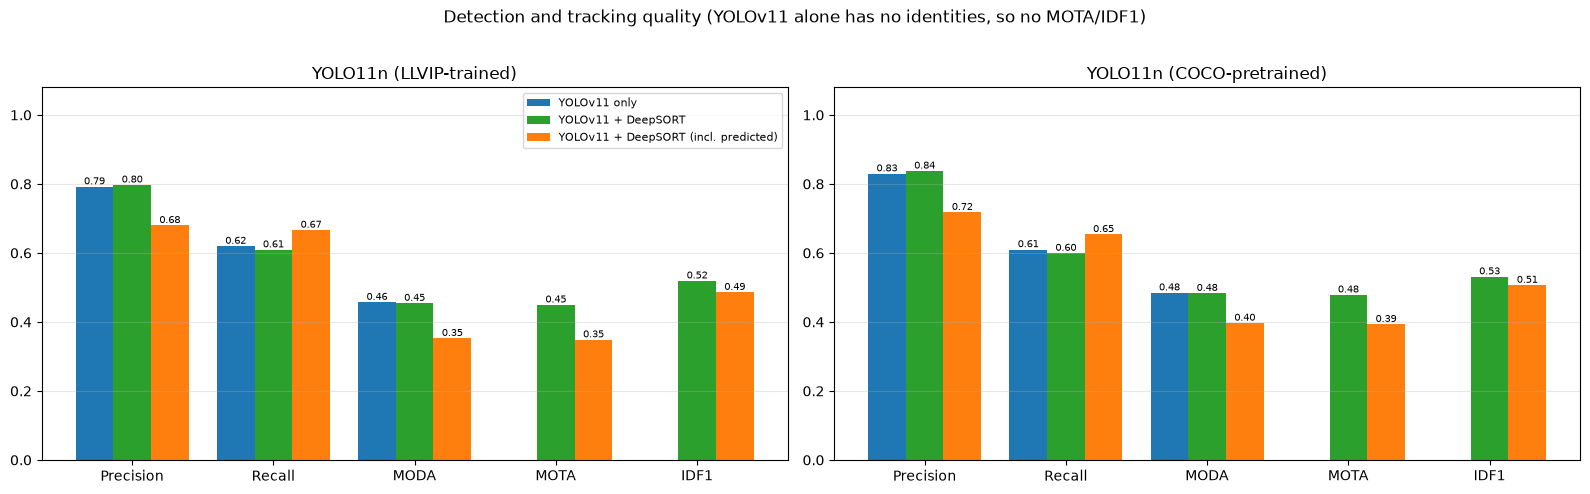

In [9]:
baseline_rows = []
baseline_tracks = {}

for detector_name, data in detector_outputs.items():
    tracks_df, update_ms = run_deepsort(data["det"], data["emb"], frame_numbers, DEFAULT_TRACKER_PARAMS)
    baseline_tracks[detector_name] = tracks_df

    timing = data["timing"]
    skip = 10 if len(timing) > 20 else 0
    detector_ms = timing["detector_ms"].iloc[skip:].mean()
    embedding_ms = timing["embedding_ms"].iloc[skip:].mean()

    metrics = evaluate_systems(data["det"], tracks_df, frame_numbers)
    for system in SYSTEM_ORDER:
        row = {"Detector": detector_name, "System": system, **metrics[system]}
        row["ms per frame"] = detector_ms if system == SYSTEM_YOLO else detector_ms + embedding_ms + update_ms
        baseline_rows.append(row)

baseline_df = pd.DataFrame(baseline_rows).set_index(["Detector", "System"])
baseline_df["FPS"] = 1000.0 / baseline_df["ms per frame"]

display(baseline_df[
    ["Boxes produced", "TP", "FP", "FN", "Precision", "Recall", "F1", "MODA", "MOTA", "IDF1"]
].round(3))
display(baseline_df[
    ["ID switches", "Fragmentations", "Mostly tracked", "Partially tracked", "Mostly lost",
     "GT identities", "Predicted identities", "MOTP (mean IoU)", "ms per frame", "FPS"]
].round(3))

metric_names = ["Precision", "Recall", "MODA", "MOTA", "IDF1"]
fig, axes = plt.subplots(1, len(detector_outputs), figsize=(8 * len(detector_outputs), 4.8), squeeze=False)
for ax, detector_name in zip(axes[0], detector_outputs):
    table = baseline_df.loc[detector_name]
    x = np.arange(len(metric_names))
    width = 0.8 / len(SYSTEM_ORDER)
    for i, system in enumerate(SYSTEM_ORDER):
        values = table.loc[system, metric_names].astype(float).to_numpy()
        bars = ax.bar(x + (i - 1) * width, np.nan_to_num(values), width, label=system, color=SYSTEM_COLORS[system])
        for bar, value in zip(bars, values):
            if not np.isnan(value):
                ax.text(bar.get_x() + bar.get_width() / 2, max(bar.get_height(), 0), f"{value:.2f}",
                        ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_names)
    ax.set_ylim(min(0, np.nanmin(table[metric_names].to_numpy(dtype=float)) - 0.05), 1.08)
    ax.set_title(detector_name)
    ax.grid(axis="y", alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Detection and tracking quality (YOLOv11 alone has no identities, so no MOTA/IDF1)", y=1.02)
fig.tight_layout()
save_figure(fig, "02_baseline_comparison")
plt.show()

baseline_df.to_csv(OUTPUT_DIR / "baseline_comparison.csv")

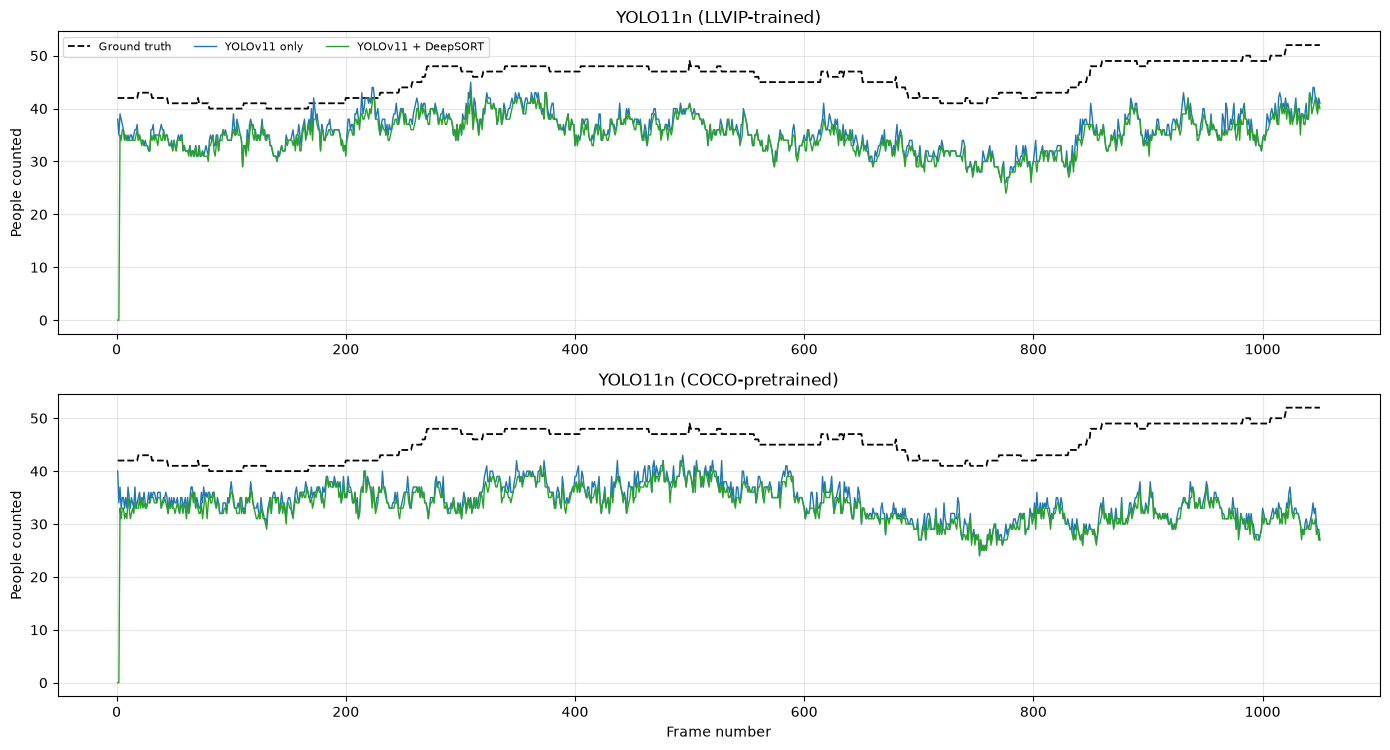

In [10]:
fig, axes = plt.subplots(len(detector_outputs), 1, figsize=(14, 3.8 * len(detector_outputs)), squeeze=False)
gt_counts = np.array([len(gt_dict.get(f, EMPTY)[0]) for f in frame_numbers])

for ax, detector_name in zip(axes[:, 0], detector_outputs):
    det_counts = detector_outputs[detector_name]["det"].groupby("frame").size().reindex(frame_numbers, fill_value=0).to_numpy()
    tracks_df = baseline_tracks[detector_name]
    ds_counts = tracks_df[tracks_df["updated"]].groupby("frame").size().reindex(frame_numbers, fill_value=0).to_numpy()
    ax.plot(frame_numbers, gt_counts, color="black", linestyle="--", linewidth=1.3, label="Ground truth")
    ax.plot(frame_numbers, det_counts, color=SYSTEM_COLORS[SYSTEM_YOLO], linewidth=1, label=SYSTEM_YOLO)
    ax.plot(frame_numbers, ds_counts, color=SYSTEM_COLORS[SYSTEM_DS], linewidth=1, label=SYSTEM_DS)
    ax.set_title(detector_name)
    ax.set_ylabel("People counted")
    ax.grid(alpha=0.3)
axes[-1, 0].set_xlabel("Frame number")
axes[0, 0].legend(fontsize=8, ncol=3)
fig.tight_layout()
save_figure(fig, "03_counts_per_frame")
plt.show()

,Detector,Parameter,Value,Is default,MOTA,IDF1,Precision,Recall,ID switches,Fragmentations,Mostly tracked,Mostly lost,Predicted identities,Update ms/frame
0,YOLO11n (LLVIP-trained),max_age,5.0,False,0.452,0.489,0.805,0.604,264,564,21,15,438,277.778
1,YOLO11n (LLVIP-trained),max_age,15.0,False,0.451,0.520,0.799,0.608,236,606,21,15,310,278.598
2,YOLO11n (LLVIP-trained),max_age,30.0,True,0.450,0.519,0.797,0.609,221,615,21,15,244,278.328
3,YOLO11n (LLVIP-trained),max_age,60.0,False,0.448,0.521,0.795,0.610,226,625,21,15,194,278.680
4,YOLO11n (LLVIP-trained),n_init,1.0,False,0.446,0.518,0.792,0.612,241,628,21,16,290,277.474
5,YOLO11n (LLVIP-trained),n_init,3.0,True,0.450,0.519,0.797,0.609,221,615,21,15,244,277.648
6,YOLO11n (LLVIP-trained),n_init,5.0,False,0.455,0.531,0.806,0.604,164,589,21,16,192,276.751
7,YOLO11n (LLVIP-trained),max_cosine_distance,0.1,False,0.448,0.489,0.802,0.602,275,562,21,16,457,272.383
8,YOLO11n (LLVIP-trained),max_cosine_distance,0.2,True,0.450,0.519,0.797,0.609,221,615,21,15,244,275.634
9,YOLO11n (LLVIP-trained),max_cosine_distance,0.4,False,0.444,0.494,0.792,0.609,254,617,21,15,180,277.011


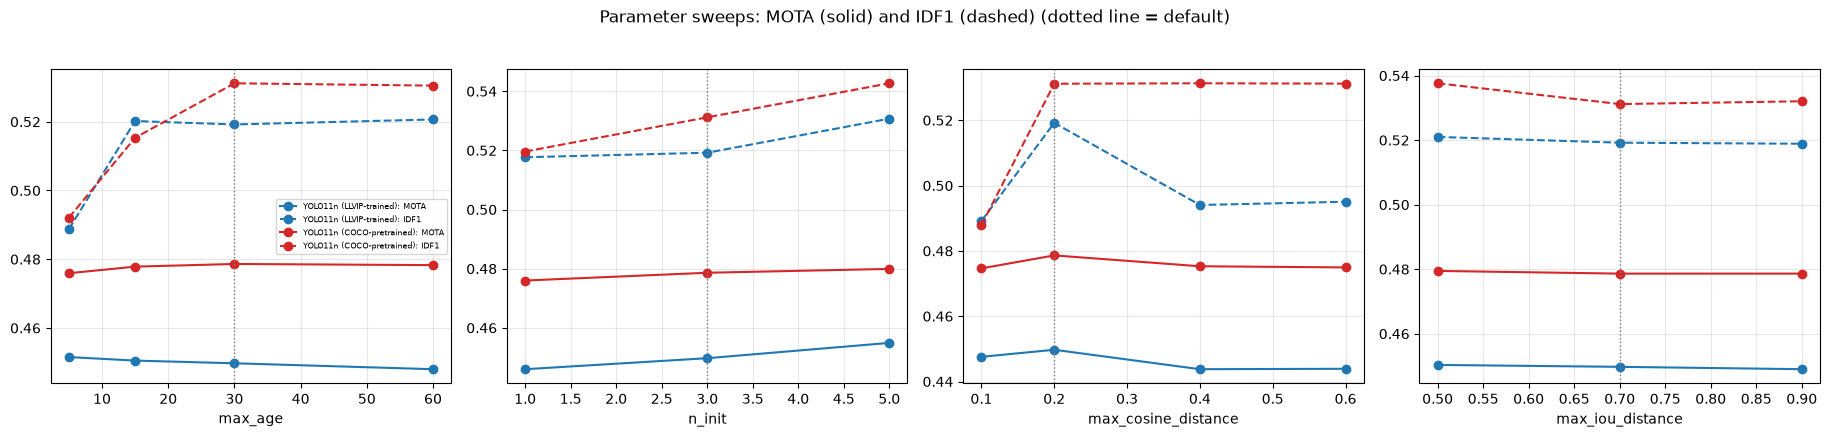

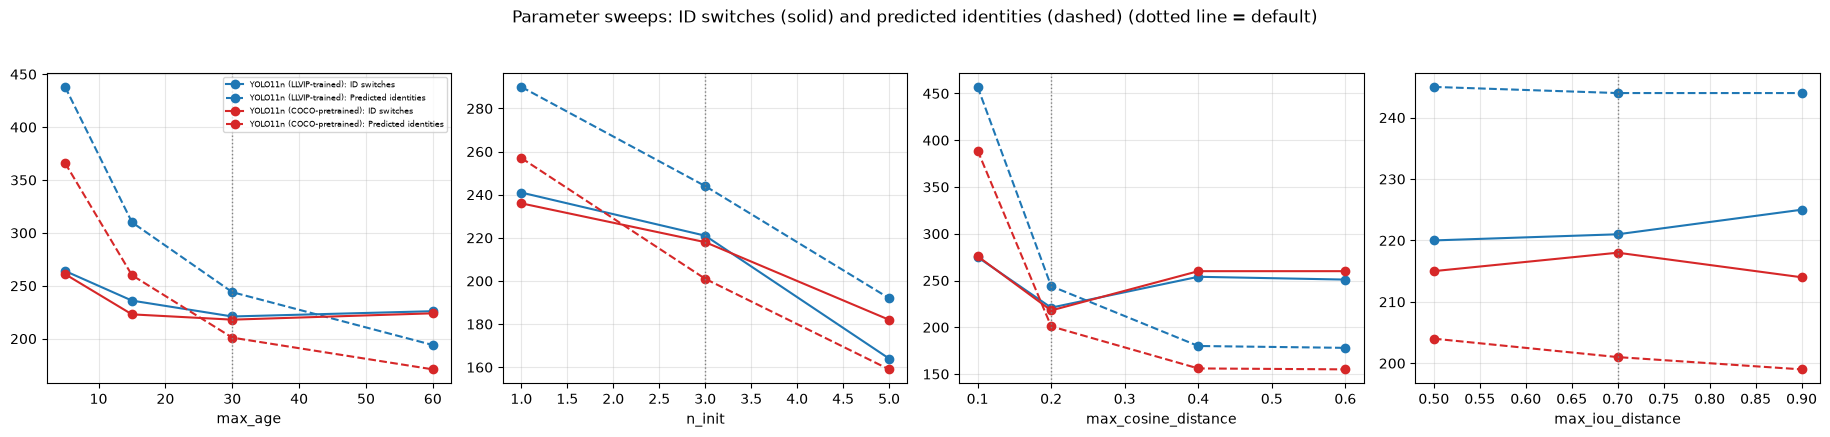

In [11]:
# One parameter at a time around the defaults; DeepSORT output = boxes matched to a detection

sweep_rows = []
for detector_name, data in detector_outputs.items():
    for parameter, values in SWEEPS.items():
        for value in values:
            params = {**DEFAULT_TRACKER_PARAMS, parameter: value}
            tracks_df, update_ms = run_deepsort(data["det"], data["emb"], frame_numbers, params)
            updated = tracks_df[tracks_df["updated"]]
            m = evaluate_sequence(frame_numbers, gt_dict, ignore_dict, to_frame_dict(updated, "track_id"))
            sweep_rows.append(
                {
                    "Detector": detector_name, "Parameter": parameter, "Value": value,
                    "Is default": DEFAULT_TRACKER_PARAMS[parameter] == value,
                    "MOTA": m["MOTA"], "IDF1": m["IDF1"], "Precision": m["Precision"], "Recall": m["Recall"],
                    "ID switches": m["ID switches"], "Fragmentations": m["Fragmentations"],
                    "Mostly tracked": m["Mostly tracked"], "Mostly lost": m["Mostly lost"],
                    "Predicted identities": m["Predicted identities"], "Update ms/frame": update_ms,
                }
            )

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(OUTPUT_DIR / "parameter_sweeps.csv", index=False)
display(sweep_df.round(3))

parameters = list(SWEEPS)
for figure_name, metric_pairs, title in [
    ("04_sweeps_mota_idf1", [("MOTA", "-"), ("IDF1", "--")], "MOTA (solid) and IDF1 (dashed)"),
    ("05_sweeps_identity_errors", [("ID switches", "-"), ("Predicted identities", "--")],
     "ID switches (solid) and predicted identities (dashed)"),
]:
    fig, axes = plt.subplots(1, len(parameters), figsize=(4.6 * len(parameters), 4.2), squeeze=False)
    for ax, parameter in zip(axes[0], parameters):
        for color, detector_name in zip(DETECTOR_COLORS, detector_outputs):
            subset = sweep_df[(sweep_df["Detector"] == detector_name) & (sweep_df["Parameter"] == parameter)]
            for metric, linestyle in metric_pairs:
                ax.plot(subset["Value"], subset[metric], linestyle, marker="o", color=color,
                        label=f"{detector_name}: {metric}")
        default_value = DEFAULT_TRACKER_PARAMS[parameter]
        ax.axvline(default_value, color="gray", linestyle=":", linewidth=1)
        ax.set_xlabel(parameter)
        ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=6)
    fig.suptitle(f"Parameter sweeps: {title} (dotted line = default)", y=1.03)
    fig.tight_layout()
    save_figure(fig, figure_name)
    plt.show()

if RUN_FULL_GRID:
    grid_rows = []
    for detector_name, data in detector_outputs.items():
        for combo in itertools.product(*SWEEPS.values()):
            params = {**DEFAULT_TRACKER_PARAMS, **dict(zip(SWEEPS, combo))}
            tracks_df, _ = run_deepsort(data["det"], data["emb"], frame_numbers, params)
            m = evaluate_sequence(frame_numbers, gt_dict, ignore_dict,
                                  to_frame_dict(tracks_df[tracks_df["updated"]], "track_id"))
            grid_rows.append({"Detector": detector_name, **dict(zip(SWEEPS, combo)),
                              "MOTA": m["MOTA"], "IDF1": m["IDF1"], "ID switches": m["ID switches"]})
    grid_df = pd.DataFrame(grid_rows).sort_values("IDF1", ascending=False)
    grid_df.to_csv(OUTPUT_DIR / "parameter_grid.csv", index=False)
    display(grid_df.head(10).round(3))

,Detector,Keep every n-th frame,Seconds between frames,GT boxes with IoU >= 0.3 vs previous frame (%),YOLO recall,DeepSORT recall,DeepSORT precision,DeepSORT MOTA,DeepSORT IDF1,DeepSORT ID switches,Predicted identities
0,YOLO11n (LLVIP-trained),1,0.033,99.922,0.620,0.609,0.797,0.450,0.519,221,244
1,YOLO11n (COCO-pretrained),1,0.033,99.922,0.610,0.599,0.838,0.479,0.531,218,201
2,YOLO11n (LLVIP-trained),2,0.067,99.844,0.619,0.603,0.798,0.443,0.559,160,168
3,YOLO11n (COCO-pretrained),2,0.067,99.844,0.609,0.591,0.839,0.471,0.561,152,154
4,YOLO11n (LLVIP-trained),3,0.100,99.766,0.619,0.595,0.798,0.436,0.547,126,139
5,YOLO11n (COCO-pretrained),3,0.100,99.766,0.611,0.585,0.835,0.462,0.536,127,129
6,YOLO11n (LLVIP-trained),5,0.167,99.630,0.617,0.581,0.795,0.423,0.576,78,117
7,YOLO11n (COCO-pretrained),5,0.167,99.630,0.610,0.574,0.836,0.450,0.549,105,109
8,YOLO11n (LLVIP-trained),10,0.333,98.068,0.620,0.552,0.785,0.384,0.546,78,101
9,YOLO11n (COCO-pretrained),10,0.333,98.068,0.611,0.541,0.838,0.423,0.547,63,104


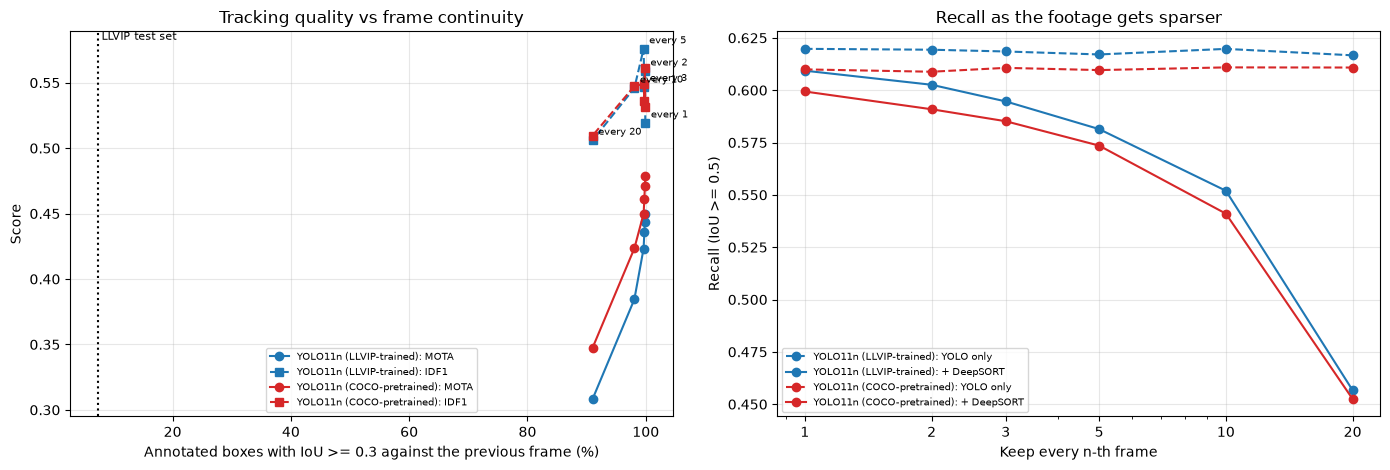

In [12]:
# Keep every n-th frame so the footage gets progressively less continuous, like the LLVIP test set.
# The tracker keeps its default settings, so max_age=30 now spans 30 *kept* frames.

skip_rows = []
for step in FRAME_STEPS:
    kept = frame_numbers[::step]
    overlap_values = best_iou_to_previous_frame(gt_dict, kept)
    continuity = float((overlap_values >= 0.3).mean() * 100) if len(overlap_values) else float("nan")

    for detector_name, data in detector_outputs.items():
        tracks_df, _ = run_deepsort(data["det"], data["emb"], kept, DEFAULT_TRACKER_PARAMS)
        m = evaluate_systems(data["det"], tracks_df, kept)
        skip_rows.append(
            {
                "Detector": detector_name, "Keep every n-th frame": step,
                "Seconds between frames": step / FRAME_RATE,
                "GT boxes with IoU >= 0.3 vs previous frame (%)": continuity,
                "YOLO recall": m[SYSTEM_YOLO]["Recall"],
                "DeepSORT recall": m[SYSTEM_DS]["Recall"],
                "DeepSORT precision": m[SYSTEM_DS]["Precision"],
                "DeepSORT MOTA": m[SYSTEM_DS]["MOTA"],
                "DeepSORT IDF1": m[SYSTEM_DS]["IDF1"],
                "DeepSORT ID switches": m[SYSTEM_DS]["ID switches"],
                "Predicted identities": m[SYSTEM_DS]["Predicted identities"],
            }
        )

skip_df = pd.DataFrame(skip_rows)
skip_df.to_csv(OUTPUT_DIR / "frame_skip_stress_test.csv", index=False)
display(skip_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for color, detector_name in zip(DETECTOR_COLORS, detector_outputs):
    subset = skip_df[skip_df["Detector"] == detector_name]
    x = subset["GT boxes with IoU >= 0.3 vs previous frame (%)"]
    axes[0].plot(x, subset["DeepSORT MOTA"], "-o", color=color, label=f"{detector_name}: MOTA")
    axes[0].plot(x, subset["DeepSORT IDF1"], "--s", color=color, label=f"{detector_name}: IDF1")
    if detector_name == next(iter(detector_outputs)):
        for xi, yi, step in zip(x, subset["DeepSORT IDF1"], subset["Keep every n-th frame"]):
            axes[0].annotate(f"every {step}", (xi, yi), textcoords="offset points", xytext=(4, 4), fontsize=7)
    axes[1].plot(subset["Keep every n-th frame"], subset["YOLO recall"], "--", marker="o", color=color,
                 label=f"{detector_name}: YOLO only")
    axes[1].plot(subset["Keep every n-th frame"], subset["DeepSORT recall"], "-", marker="o", color=color,
                 label=f"{detector_name}: + DeepSORT")

axes[0].axvline(LLVIP_REFERENCE_PCT, color="black", linestyle=":", linewidth=1.5)
axes[0].text(LLVIP_REFERENCE_PCT, axes[0].get_ylim()[1], " LLVIP test set", va="top", fontsize=8)
axes[0].set_xlabel("Annotated boxes with IoU >= 0.3 against the previous frame (%)")
axes[0].set_ylabel("Score")
axes[0].set_title("Tracking quality vs frame continuity")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=7)

axes[1].set_xlabel("Keep every n-th frame")
axes[1].set_ylabel("Recall (IoU >= 0.5)")
axes[1].set_title("Recall as the footage gets sparser")
axes[1].set_xscale("log")
axes[1].set_xticks(FRAME_STEPS)
axes[1].set_xticklabels([str(s) for s in FRAME_STEPS])
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=7)

fig.tight_layout()
save_figure(fig, "06_frame_skip_stress_test")
plt.show()

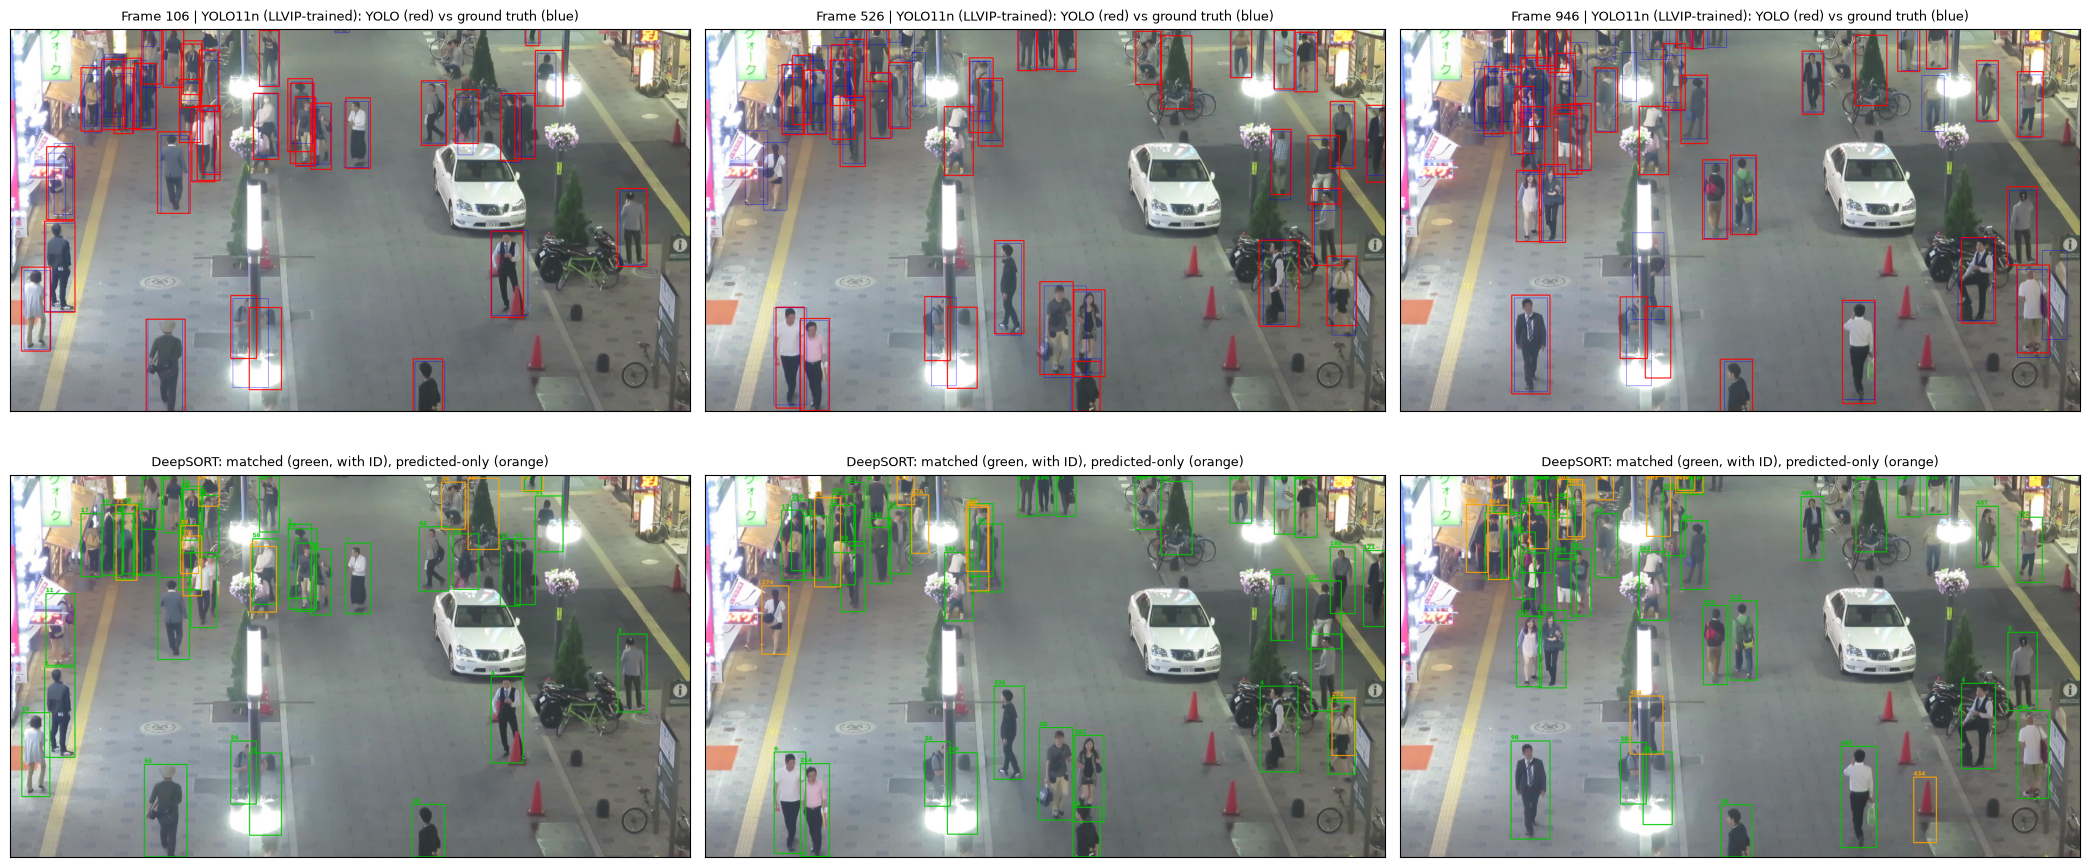

In [13]:
def draw_boxes(image_bgr, boxes, color, labels=None, thickness=2):
    output = image_bgr.copy()
    for i, (x1, y1, x2, y2) in enumerate(boxes):
        cv2.rectangle(output, (int(x1), int(y1)), (int(x2), int(y2)), color, thickness)
        if labels is not None:
            cv2.putText(output, str(labels[i]), (int(x1), max(14, int(y1) - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return output


primary = next(iter(detector_outputs))
primary_tracks = baseline_tracks[primary]
primary_det = detector_outputs[primary]["det"]
picks = [frame_numbers[int(len(frame_numbers) * q)] for q in (0.1, 0.5, 0.9)]

fig, axes = plt.subplots(2, len(picks), figsize=(7 * len(picks), 9.5), squeeze=False)
for col, f in enumerate(picks):
    image = cv2.imread(str(IMAGE_DIR / frames_df.loc[frames_df["frame_number"] == f, "image_name"].iloc[0]))
    gt_boxes = gt_dict.get(f, EMPTY)[1]
    det_boxes = primary_det[primary_det["frame"] == f][["x1", "y1", "x2", "y2"]].to_numpy()
    frame_tracks = primary_tracks[(primary_tracks["frame"] == f)]
    matched = frame_tracks[frame_tracks["updated"]]
    predicted = frame_tracks[~frame_tracks["updated"]]

    top = draw_boxes(image, gt_boxes, (255, 0, 0), thickness=1)
    top = draw_boxes(top, det_boxes, (0, 0, 255), thickness=2)
    bottom = draw_boxes(image, matched[["x1", "y1", "x2", "y2"]].to_numpy(), (0, 200, 0),
                        labels=matched["track_id"].tolist())
    bottom = draw_boxes(bottom, predicted[["x1", "y1", "x2", "y2"]].to_numpy(), (0, 165, 255),
                        labels=predicted["track_id"].tolist())
    axes[0, col].imshow(cv2.cvtColor(top, cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"Frame {f} | {primary}: YOLO (red) vs ground truth (blue)", fontsize=9)
    axes[1, col].imshow(cv2.cvtColor(bottom, cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"DeepSORT: matched (green, with ID), predicted-only (orange)", fontsize=9)
    for ax in (axes[0, col], axes[1, col]):
        ax.set_xticks([])
        ax.set_yticks([])

fig.tight_layout()
save_figure(fig, "07_qualitative_examples")
plt.show()

## Summary

In [14]:
summary = baseline_df[
    ["Boxes produced", "Precision", "Recall", "MODA", "MOTA", "IDF1", "ID switches",
     "Predicted identities", "GT identities", "ms per frame", "FPS"]
].round(3)
display(summary)
summary.to_csv(OUTPUT_DIR / "summary.csv")
print("Tables and figures saved in:", OUTPUT_DIR)

Boxes produced  \
Detector                  System                                                 
YOLO11n (LLVIP-trained)   YOLOv11 only                                   37206   
                          YOLOv11 + DeepSORT                             36347   
                          YOLOv11 + DeepSORT (incl. predicted)           46611   
YOLO11n (COCO-pretrained) YOLOv11 only                                   34964   
                          YOLOv11 + DeepSORT                             34030   
                          YOLOv11 + DeepSORT (incl. predicted)           43312   

                                                                Precision  \
Detector                  System                                            
YOLO11n (LLVIP-trained)   YOLOv11 only                              0.792   
                          YOLOv11 + DeepSORT                        0.797   
                          YOLOv11 + DeepSORT (incl. predicted)      0.680   
YOLO11n (COCO-pretrained) YOLOv11 only                              0.830   
                          YOLOv11 + DeepSORT                        0.838   
                          YOLOv11 + DeepSORT (incl. predicted)      0.718   

                                                                Recall   MODA  \
Detector                  System                                                
YOLO11n (LLVIP-trained)   YOLOv11 only                           0.620  0.457   
                          YOLOv11 + DeepSORT                     0.609  0.454   
                          YOLOv11 + DeepSORT (incl. predicted)   0.666  0.353   
YOLO11n (COCO-pretrained) YOLOv11 only                           0.610  0.485   
                          YOLOv11 + DeepSORT                     0.599  0.483   
                          YOLOv11 + DeepSORT (incl. predicted)   0.654  0.397   

                                                                 MOTA   IDF1  \
Detector                  System                                               
YOLO11n (LLVIP-trained)   YOLOv11 only                            NaN    NaN   
                          YOLOv11 + DeepSORT                    0.450  0.519   
                          YOLOv11 + DeepSORT (incl. predicted)  0.349  0.486   
YOLO11n (COCO-pretrained) YOLOv11 only                            NaN    NaN   
                          YOLOv11 + DeepSORT                    0.479  0.531   
                          YOLOv11 + DeepSORT (incl. predicted)  0.393  0.507   

                                                                ID switches  \
Detector                  System                                              
YOLO11n (LLVIP-trained)   YOLOv11 only                                  NaN   
                          YOLOv11 + DeepSORT                          221.0   
                          YOLOv11 + DeepSORT (incl. predicted)        191.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                  NaN   
                          YOLOv11 + DeepSORT                          218.0   
                          YOLOv11 + DeepSORT (incl. predicted)        172.0   

                                                                Predicted identities  \
Detector                  System                                                       
YOLO11n (LLVIP-trained)   YOLOv11 only                                           NaN   
                          YOLOv11 + DeepSORT                                   244.0   
                          YOLOv11 + DeepSORT (incl. predicted)                 245.0   
YOLO11n (COCO-pretrained) YOLOv11 only                                           NaN   
                          YOLOv11 + DeepSORT                                   201.0   
                          YOLOv11 + DeepSORT (incl. predicted)                 204.0   

                                                                GT identities  \
Detector                  System                                                


Tables and figures saved in: /home/arjun/lli-pedestrian/runs/deepsort_continuous
